# 1. SETUP & DATA LOADING

In [1]:
pip install pandas matplotlib seaborn numpy 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
train = pd.read_csv('train.csv')
train.tail()

C:\Users\Afan\AppData\Local\Temp\ipykernel_11136\2873746213.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('train.csv')


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1
1017208,1115,2,2013-01-01,0,0,0,0,a,1


In [4]:
store = pd.read_csv('store.csv')
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [5]:
train.shape

(1017209, 9)

In [6]:
train.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


# 2. DATA CLEANING & IMPUTATION

In [7]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [8]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [9]:
store.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 98.0 KB


In [10]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 79.5+ MB


In [11]:
train.duplicated().sum()

np.int64(0)

In [12]:
train.columns = train.columns.str.lower()

In [13]:
store.columns = store.columns.str.lower()

In [14]:
df = train.merge(store , on = 'store' , how = 'left')

In [15]:
train['date'] = pd.to_datetime(train['date'] , format = '%Y-%m-%d')

In [16]:
df['date'] = pd.to_datetime(df['date'] , format = '%Y-%m-%d')

In [17]:
df = df.sort_values(["store", "date"])

In [18]:
df.head()

,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval
1016095,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1014980,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1013865,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1012750,1,5,2013-01-04,4486,619,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1011635,1,6,2013-01-05,4997,635,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN


In [19]:
df.isnull().sum()

store                             0
dayofweek                         0
date                              0
sales                             0
customers                         0
open                              0
promo                             0
stateholiday                      0
schoolholiday                     0
storetype                         0
assortment                        0
competitiondistance            2642
competitionopensincemonth    323348
competitionopensinceyear     323348
promo2                            0
promo2sinceweek              508031
promo2sinceyear              508031
promointerval                508031
dtype: int64

In [20]:
df['competitiondistance'] = df['competitiondistance'].fillna(df['competitiondistance'].median())

In [21]:
df['competition_missing'] = df['competitionopensincemonth'].isna().astype(int)

In [22]:
df['competitionopensincemonth'] = df['competitionopensincemonth'].fillna(0)
df['competitionopensinceyear'] = df['competitionopensinceyear'].fillna(0)

In [23]:
pd.crosstab(df['promo2'], df['promointerval'].isna())

promointerval,False,True
promo2,,
0,0,508031
1,509178,0


In [24]:
df['promo2_active'] = df['promo2']

In [25]:
df["promo2sinceweek"] = df["promo2sinceweek"].fillna(0)
df["promo2sinceyear"] = df["promo2sinceyear"].fillna(0)
df["promointerval"] = df["promointerval"].fillna('None')

In [26]:
df[df["sales"] < 0]

,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval,competition_missing,promo2_active


# 3. **EDA**

**1. Sales Distribution**

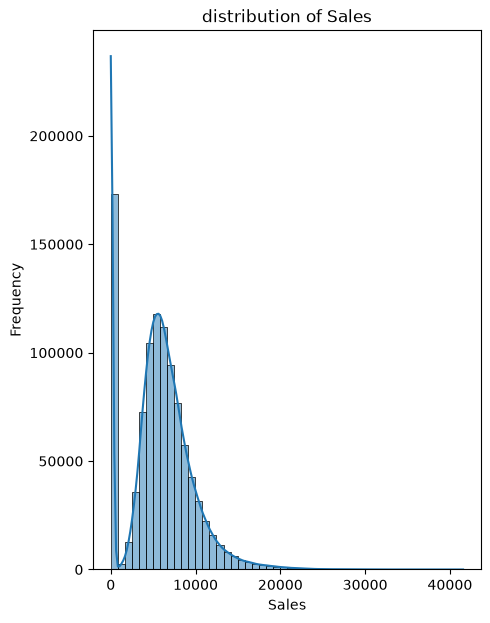

In [27]:
plt.figure(figsize = (5,7))
sns.histplot(df['sales'] , bins = 50 , kde = True)
plt.title('distribution of Sales')
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

### Insight

The sales distribution helps identify typical sales ranges, skewness, and unusually high sales values. These patterns are useful for understanding variability and potential outliers before model training.


**2. Monthly Sales Trend**

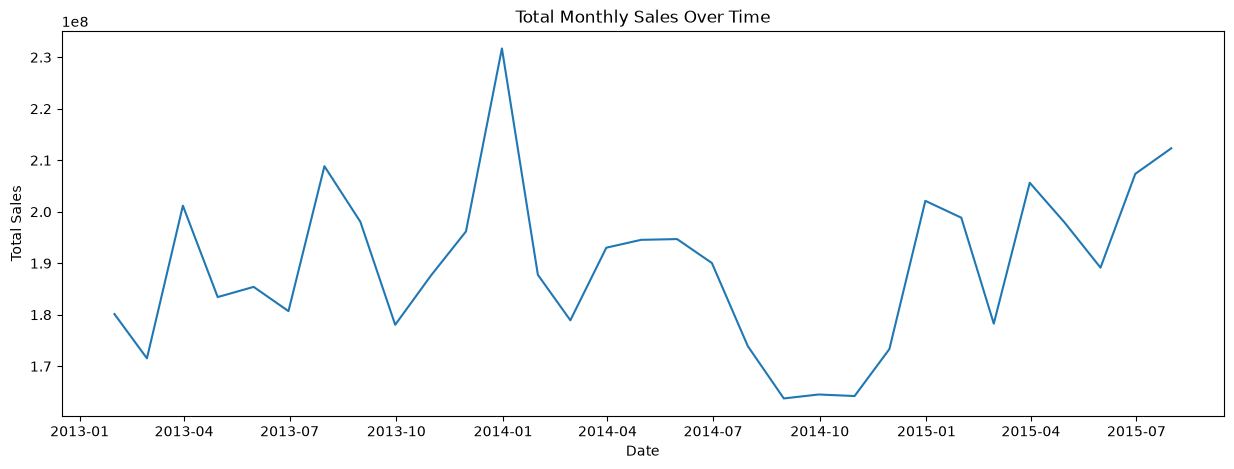

In [28]:
monthly_sales = (df.set_index('date')['sales'].resample('ME').sum().reset_index())
plt.figure(figsize=(15, 5))

plt.plot(monthly_sales['date'], monthly_sales['sales'])

plt.title('Total Monthly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.show()

### Insight

Monthly aggregation helps reveal changes in sales over time and potential seasonal patterns. These temporal patterns motivate the use of calendar features in the forecasting model.

**3. Sales by Day of Week**

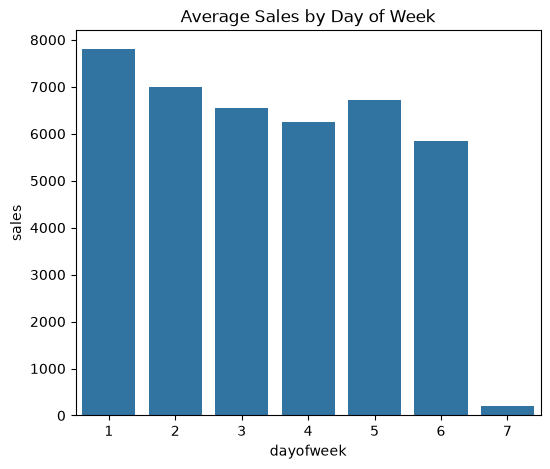

In [29]:
day_sales = (df.groupby('dayofweek')['sales'].mean().reset_index())

plt.figure(figsize = (6 , 5))
sns.barplot( data = day_sales , x = 'dayofweek' , y = 'sales')
plt.title('Average Sales by Day of Week')

plt.show()

### Insight

Comparing sales across weekdays helps identify recurring weekly demand patterns. Day-of-week information can help the model distinguish between days with different typical sales behavior.


**4. Promotion vs Sales**

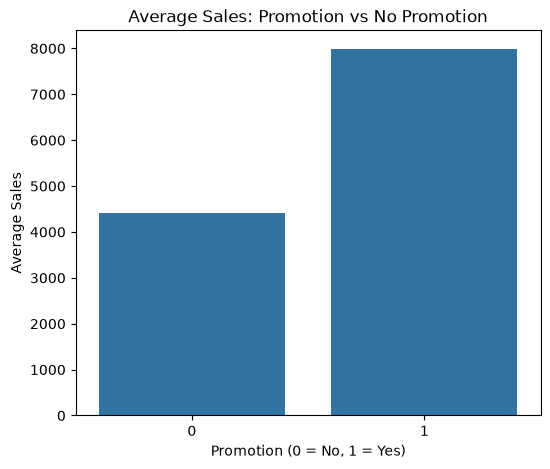

In [30]:
promo_sales = (df.groupby('promo')['sales'].mean().reset_index())

plt.figure(figsize=(6,5))
sns.barplot(data = promo_sales , x = 'promo' , y = 'sales')
plt.title('Average Sales: Promotion vs No Promotion')
plt.xlabel('Promotion (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')

plt.show()

### Insight

Comparing promotional and non-promotional sales helps assess how demand differs across promotional conditions. The observed association does not, by itself, prove that promotions cause higher sales.


**5. Customers vs Sales**

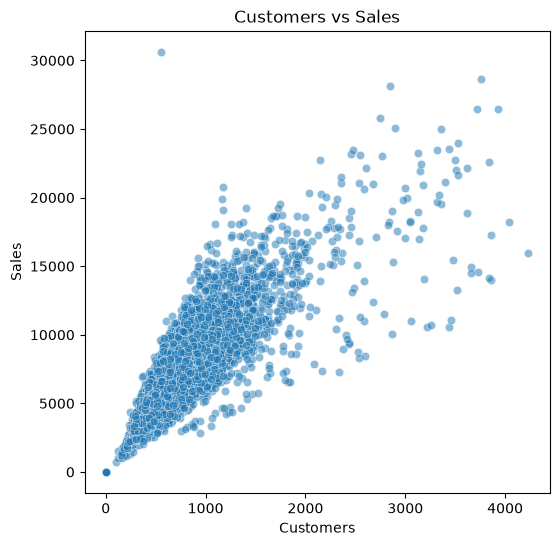

In [31]:
plt.figure(figsize=(6,6))

sns.scatterplot(data = df.sample(10000) , x = 'customers' , y = 'sales' , alpha = 0.5)
plt.title('Customers vs Sales')
plt.xlabel('Customers')
plt.ylabel('Sales')

plt.show()

### Insight

Examining customers and sales together helps assess whether higher customer traffic is associated with higher revenue. This also highlights the potential predictive value of customer counts, although customer counts may not be available when making a genuine future forecast.


**6. Sales by Store Type**

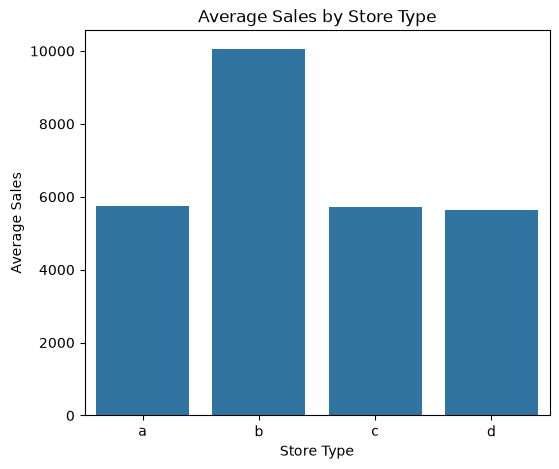

In [32]:
storetype_sales = (df.groupby('storetype')['sales'].mean().reset_index())

plt.figure(figsize=(6,5))
sns.barplot(data = storetype_sales, x='storetype' , y = 'sales')
plt.title('Average Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Sales')

plt.show()

### Insight

Sales comparisons across store types reveal differences in typical demand and variability. Store type can provide useful context when forecasting sales for different retail locations.


**7. Top 10 Stores**

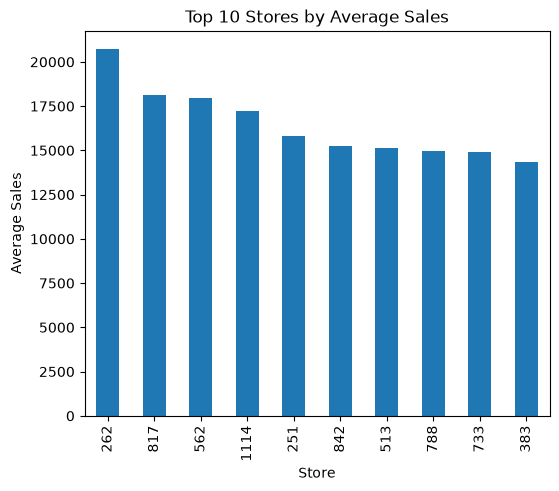

In [33]:
top_stores = (df.groupby('store')['sales'].mean().sort_values(ascending = False).head(10))

plt.figure(figsize=(6,5))
top_stores.plot(kind = 'bar')
plt.title('Top 10 Stores by Average Sales')
plt.xlabel('Store')
plt.ylabel('Average Sales')

plt.show()

### Insight

Ranking stores by total sales identifies locations that contribute strongly to overall sales volume. These comparisons describe historical performance and do not necessarily indicate which stores are easiest to forecast.


**8. Open vs Closed Stores**

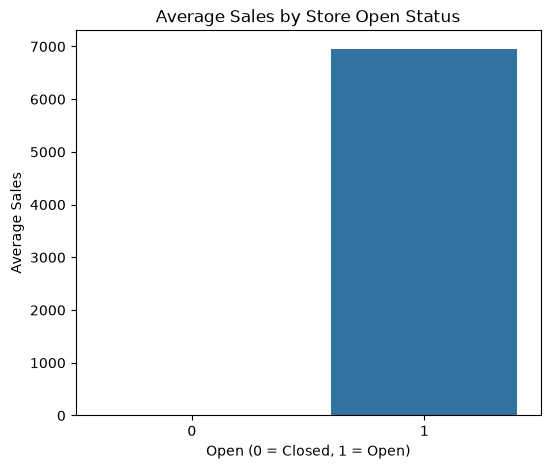

In [34]:
open_sales = (df.groupby('open')['sales'].mean().reset_index())

plt.figure(figsize = (6,5))

sns.barplot(data = open_sales , x = 'open' , y = 'sales')
plt.title('Average Sales by Store Open Status')
plt.xlabel('Open (0 = Closed, 1 = Open)')
plt.ylabel('Average Sales')

plt.show()

### Insight

Closed stores generally have zero recorded sales, so opening status is important when interpreting sales data. The forecasting model focuses on open-store observations to predict positive trading-day sales.


**9. School Holiday vs Sales**

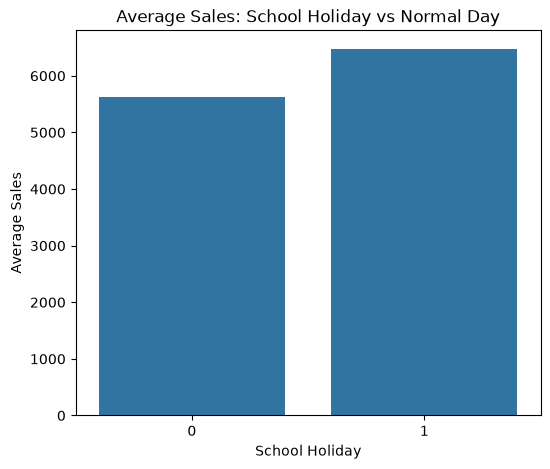

In [35]:
holiday_sales = (df.groupby('schoolholiday')['sales'].mean().reset_index())

plt.figure(figsize=(6,5))
sns.barplot(data = holiday_sales , x= 'schoolholiday' , y = 'sales')
plt.title('Average Sales: School Holiday vs Normal Day')
plt.xlabel('School Holiday')
plt.ylabel('Average Sales')

plt.show()

### Insight

Comparing sales across school-holiday conditions helps investigate whether demand differs during holiday periods. The direction and size of any difference should be determined from the plotted results rather than assumed in advance.


**10. Correlation Matrix**

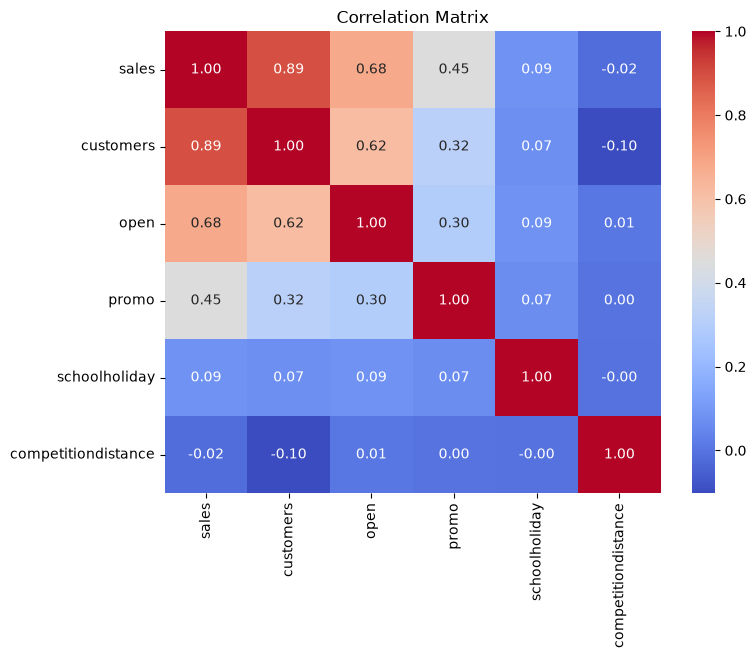

In [36]:
numeric_cols = ['sales' , 'customers' , 'open' , 'promo' , 'schoolholiday' , 'competitiondistance']

corr = df[numeric_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr , annot = True , cmap= 'coolwarm' , fmt = '.2f')
plt.title('Correlation Matrix')

plt.show()

### Insight

Correlation analysis helps identify linear relationships between numerical variables. Strong correlations can provide useful context for feature selection, but correlation alone does not establish causation or guarantee predictive usefulness.


**11. Demand Variability**

In [37]:
store_stats = (df.groupby('store')['sales'].agg(['mean' , 'std' , 'min' , 'max']).sort_values('mean' , ascending= False))
store_stats.head(10)

,mean,std,min,max
store,,,,
262,20718.515924,4668.877584,13210,38722
817,18108.139066,9183.542868,0,38025
562,17969.556263,2931.927599,8498,28680
1114,17200.196391,8343.045630,0,35697
251,15814.087049,7924.000164,0,35350
842,15242.114776,7914.631921,0,35154
513,15129.942675,7426.948520,0,31094
788,14949.194268,7303.796656,0,32170
733,14933.288747,1838.044097,6838,22137


### Insight

Demand variability highlights differences in sales stability across stores or time periods. Highly variable sales can be more difficult to predict accurately and may require closer error analysis.


# 5.  Feature Engineering

In [38]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['dayofweek'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

In [39]:
df = df.sort_values(['store' , 'date'])

In [40]:
df['lag_1'] = df.groupby('store')['sales'].shift(1)
df['lag_7'] = df.groupby('store')['sales'].shift(7)
df['lag_14'] = df.groupby('store')['sales'].shift(14)
df['lag_28'] = df.groupby('store')['sales'].shift(28)

In [41]:
df['rolling_mean_7'] = (df.groupby('store')['sales'].transform(lambda x:x.shift(1).rolling(7).mean()))
df['rolling_mean_14'] = (df.groupby('store')['sales'].transform(lambda x: x.shift(1).rolling(14).mean()))
df['rolling_mean_28'] = (df.groupby('store')['sales'].transform(lambda x: x.shift(1).rolling(28).mean()))

In [42]:
df['rolling_std_7'] = (df.groupby('store')['sales'].transform(lambda x: x.shift(1).rolling(7).std()))
df['rolling_std_28'] = (df.groupby('store')['sales'].transform(lambda x: x.shift(1).rolling(28).std()))

### Target Definition

The target is constructed by shifting sales by one observation within each store after filtering to open-store records. Consequently, the model predicts sales for the next observed open day. This distinction matters when a store is closed on intervening calendar days.


In [43]:
df_model = df[df['open'] == 1].copy()
df_model = df_model.sort_values(['store' , 'date'])

In [44]:
df_model['target'] = df_model.groupby('store')['sales'].shift(-1)

In [45]:
df_model = df_model.dropna(
    subset=[
        'lag_1',
        'lag_7',
        'lag_14',
        'lag_28',
        'rolling_mean_7',
        'rolling_mean_14',
        'rolling_mean_28',
        'rolling_std_7',
        'rolling_std_28',
        'target'
    ]
)

In [46]:
features = [
    'store',
    'promo',
    'schoolholiday',
    'competitiondistance',
    'promo2',
    'year',
    'month',
    'day',
    'dayofweek',
    'is_weekend',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_28',
    'rolling_mean_7',
    'rolling_mean_14',
    'rolling_mean_28',
    'rolling_std_7',
    'rolling_std_28',
    'storetype',
    'assortment',
    'stateholiday'
]

In [47]:
X = df_model[features]
y = df_model['target']

### Feature Engineering Insight

Lag features represent previous sales observations, while rolling statistics summarize recent sales levels and variability. Calendar features capture recurring temporal patterns. All historical sales features must be calculated without using future sales information.

# 6. **Train-Test Split**

In [48]:
df_model = df_model.sort_values('date')

In [49]:
split = int(len(df_model) * 0.8)

train_data = df_model.iloc[:split].copy()
test_data = df_model.iloc[split:].copy()

In [50]:
X_train = train_data[features]
y_train = train_data['target']

X_test = test_data[features]
y_test = test_data['target']

In [51]:
X_train = pd.get_dummies(X_train , columns = ['storetype' , 'assortment' , 'stateholiday'] , drop_first = True)

X_test = pd.get_dummies(X_test , columns = ['storetype' , 'assortment' , 'stateholiday'] , drop_first = True)

In [52]:
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

### Target and Splitting Insight

The target is defined as the next observed open-day sales value for each store because the data is filtered to open days before applying the shift. A chronological split preserves time order and provides a more realistic evaluation than randomly shuffling time-series observations.

# 7. Model training and comparison

In [53]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Missing values in X_train:")
print(X_train.isnull().sum().sum())

print("Missing values in X_test:")
print(X_test.isnull().sum().sum())

X_train: (654184, 28)
X_test: (163546, 28)
y_train: (654184,)
y_test: (163546,)
Missing values in X_train:
0
Missing values in X_test:
0


In [54]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [55]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

In [56]:
baseline_pred = X_test['lag_1']

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 2617.137802208553
Baseline RMSE: 3905.727024947457
Baseline R2: -0.6291458771038405


In [57]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train , y_train)
lr_pred = lr.predict(X_test)

In [58]:
MAE = mean_absolute_error(y_test , lr_pred)
RMSE = np.sqrt(mean_squared_error(y_test , lr_pred))
R2 = r2_score(y_test , lr_pred)
print(MAE , RMSE , R2)

1088.385619327419 1531.6260794283032 0.7494688653229331


In [59]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators = 100 ,random_state = 42 , n_jobs = -1)

rf.fit(X_train , y_train)
y_pred = rf.predict(X_test)

In [60]:
MAE = mean_absolute_error(y_test , y_pred)
RMSE = np.sqrt(mean_squared_error(y_test , y_pred))
R2 = r2_score(y_test , y_pred)
print(MAE ,RMSE , R2)

774.2794907243222 1175.070768998125 0.8525365989865072


In [61]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [62]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators = 500 , learning_rate = 0.05 , max_depth = 8 , random_state = 42)
xgb.fit(X_train , y_train)
xgb_pred = xgb.predict(X_test)

In [63]:
MAE = mean_absolute_error(y_test , xgb_pred)
RMSE = np.sqrt(mean_squared_error(y_test , xgb_pred))
R2 = r2_score(y_test , xgb_pred)
print(MAE , RMSE , R2)

759.2480186096761 1117.0632058228925 0.8667363529771239


### Model Comparison Insight

Comparing multiple models establishes whether machine-learning approaches improve upon a simple lag-based baseline. MAE measures average absolute error, RMSE penalizes larger errors more strongly, and R² measures the proportion of target variance explained by the model relative to a mean-prediction baseline.The models should be compared using consistent data splits and feature sets

In [64]:
results = pd.DataFrame({
    'Model' : ['Baseline' , 'Linear Regression' , 'Random Forest' , 'XGBoost'],
   
    'MAE' : [baseline_mae,
             mean_absolute_error(y_test, lr_pred),
             mean_absolute_error(y_test, y_pred),
             mean_absolute_error(y_test, xgb_pred)],
    
    'RMSE' : [baseline_rmse,
              np.sqrt(mean_squared_error(y_test, lr_pred)),
              np.sqrt(mean_squared_error(y_test, y_pred)),
              np.sqrt(mean_squared_error(y_test, xgb_pred))],

    'R2' : [baseline_r2,
            r2_score(y_test, lr_pred),
            r2_score(y_test, y_pred),
            r2_score(y_test, xgb_pred)]
        
   })
results

,Model,MAE,RMSE,R2
0,Baseline,2617.137802,3905.727025,-0.629146
1,Linear Regression,1088.385619,1531.626079,0.749469
2,Random Forest,774.279491,1175.070769,0.852537
3,XGBoost,759.248019,1117.063206,0.866736


In [65]:
print("Training period:")
print(train_data['date'].min())
print(train_data['date'].max())

print("\nTesting period:")
print(test_data['date'].min())
print(test_data['date'].max())

Training period:
2013-01-29 00:00:00
2015-02-04 00:00:00

Testing period:
2015-02-04 00:00:00
2015-07-30 00:00:00


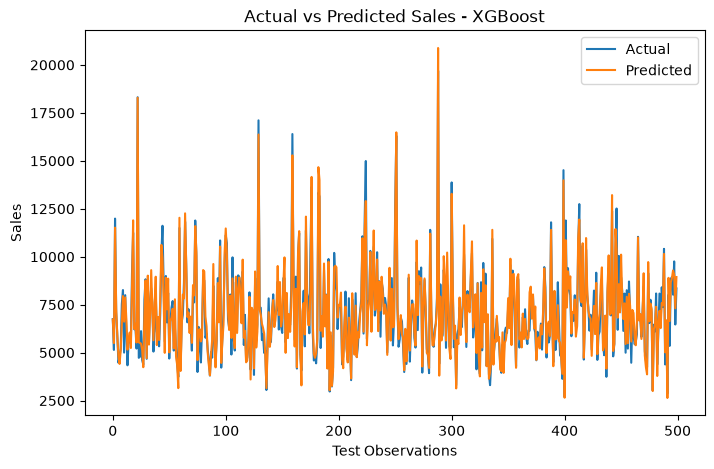

In [66]:
plt.figure(figsize=(8,5))

plt.plot(y_test.values[:500], label = 'Actual')
plt.plot(xgb_pred[:500] , label='Predicted')

plt.title('Actual vs Predicted Sales - XGBoost')
plt.xlabel('Test Observations')
plt.ylabel('Sales')

plt.legend()
plt.show()

# 8. ERROR & RESIDUAL ANALYSIS

In [67]:
residuals = y_test - xgb_pred

print(residuals.describe())

count    163546.000000
mean         21.043071
std        1116.868400
min      -16762.230469
25%        -503.201538
50%          15.591064
75%         543.121216
max       32307.042969
Name: target, dtype: float64


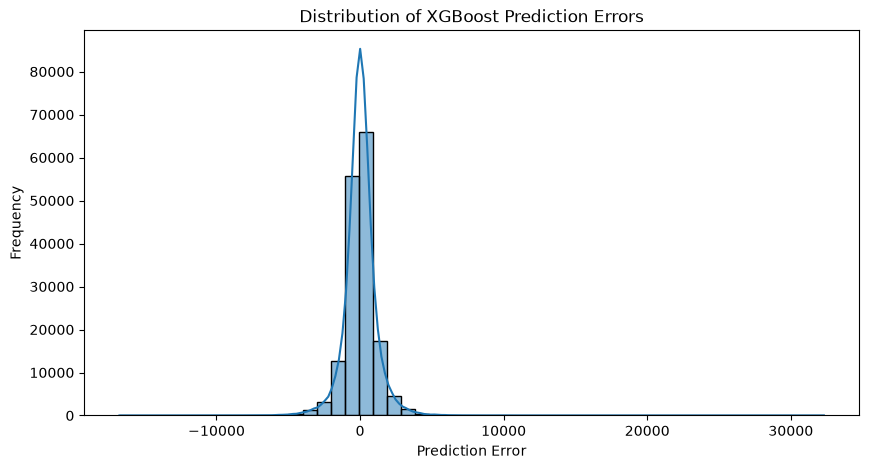

In [68]:
plt.figure(figsize=(10, 5))

sns.histplot(residuals, bins=50, kde=True)

plt.title('Distribution of XGBoost Prediction Errors')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')

plt.show()

In [69]:
importance = pd.Series(
    xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(15))

rolling_mean_28    0.565803
promo              0.104549
rolling_mean_14    0.077061
dayofweek          0.040200
rolling_mean_7     0.029247
day                0.018918
storetype_b        0.016764
month              0.015872
lag_1              0.014841
storetype_d        0.013018
storetype_c        0.012505
schoolholiday      0.010732
rolling_std_28     0.009412
year               0.009018
stateholiday_0     0.008199
dtype: float32


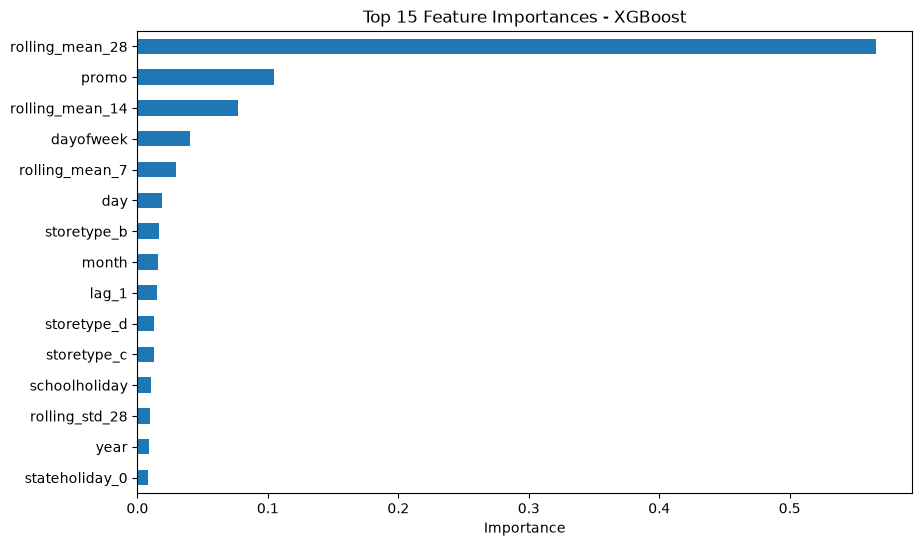

In [70]:
plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(kind='barh')

plt.title('Top 15 Feature Importances - XGBoost')
plt.xlabel('Importance')

plt.show()

In [71]:
print(df_model[['date', 'store', 'sales', 'target', 'lag_1']].head(10))

             date  store  sales  target   lag_1
984875 2013-01-29      1   3725  4601.0  4055.0
984987 2013-01-29    113   4391  6072.0  5629.0
985717 2013-01-29    843   7225  7500.0  7739.0
985718 2013-01-29    844   2886  3914.0  3465.0
985719 2013-01-29    845   3336  3628.0  3165.0
984986 2013-01-29    112   5369  5233.0  5726.0
985720 2013-01-29    846   6815  6975.0  6593.0
985721 2013-01-29    847   4948  5365.0  4853.0
984985 2013-01-29    111   4639  4980.0  4724.0
985722 2013-01-29    848   3831  4557.0  4328.0


In [72]:
error_analysis = test_data[['date' , 'store' , 'sales' , 'target']].copy()

error_analysis['predicted_sales'] = xgb_pred
error_analysis['error'] = (
    error_analysis['target'] - error_analysis['predicted_sales']
)

error_analysis['absolute_error'] = (
    error_analysis['error'].abs()
)

error_analysis.tail()

,date,store,sales,target,predicted_sales,error,absolute_error
1538,2015-07-30,424,7076,10141.0,8895.324219,1245.675781,1245.675781
2108,2015-07-30,994,5506,6816.0,6326.295410,489.704590,489.704590
1703,2015-07-30,589,6148,8001.0,7079.870117,921.129883,921.129883
1852,2015-07-30,738,9250,9504.0,10868.023438,-1364.023438,1364.023438
2229,2015-07-30,1115,8405,8680.0,8963.149414,-283.149414,283.149414


In [73]:
worst_predictions = error_analysis.sort_values(
    'absolute_error',
    ascending=False
).head(20)

worst_predictions

,date,store,sales,target,predicted_sales,error,absolute_error
46623,2015-06-20,909,22882,41551.0,9243.957031,32307.042969,32307.042969
44393,2015-06-22,909,41551,30038.0,9180.994141,20857.005859,20857.005859
192423,2015-02-09,644,22970,28242.0,7605.354492,20636.645508,20636.645508
88346,2015-05-13,262,21861,38367.0,17842.251953,20524.748047,20524.748047
38201,2015-06-27,292,3278,29161.0,9595.926758,19565.073242,19565.073242
186878,2015-02-14,674,2401,0.0,16762.230469,-16762.230469,16762.230469
76081,2015-05-24,262,30978,35159.0,18849.298828,16309.701172,16309.701172
134061,2015-04-02,262,30012,38722.0,22886.250000,15835.750000,15835.750000
191308,2015-02-10,644,28242,26818.0,11135.485352,15682.514648,15682.514648
35971,2015-06-29,292,29161,23584.0,7930.909668,15653.090332,15653.090332


In [74]:
error_analysis['error'].describe()

count    163546.000000
mean         21.043071
std        1116.868400
min      -16762.230469
25%        -503.201538
50%          15.591064
75%         543.121216
max       32307.042969
Name: error, dtype: float64

In [75]:
error_analysis['absolute_error'].describe()

count    163546.000000
mean        759.248019
std         819.375834
min           0.000000
25%         237.653564
50%         523.961670
75%         992.807251
max       32307.042969
Name: absolute_error, dtype: float64

In [76]:
error_analysis = error_analysis.merge(
    df_model[['date', 'store', 'promo']],
    on=['date', 'store'],
    how='left'
)

In [77]:
promo_error = (
    error_analysis
    .groupby('promo')['absolute_error']
    .mean()
    .reset_index()
)

promo_error

,promo,absolute_error
0,0,764.618090
1,1,752.311068


In [78]:
store_error = error_analysis.groupby('store')['absolute_error'].mean().sort_values(ascending = False)
store_error.head(15)

store
842     2244.456432
644     2224.302992
909     2092.368012
262     1922.179016
1114    1843.370416
192     1643.327844
827     1633.631876
756     1609.692597
1014    1575.838633
310     1572.120341
876     1562.801588
279     1557.503098
817     1548.470917
421     1538.087687
1027    1523.059811
Name: absolute_error, dtype: float64

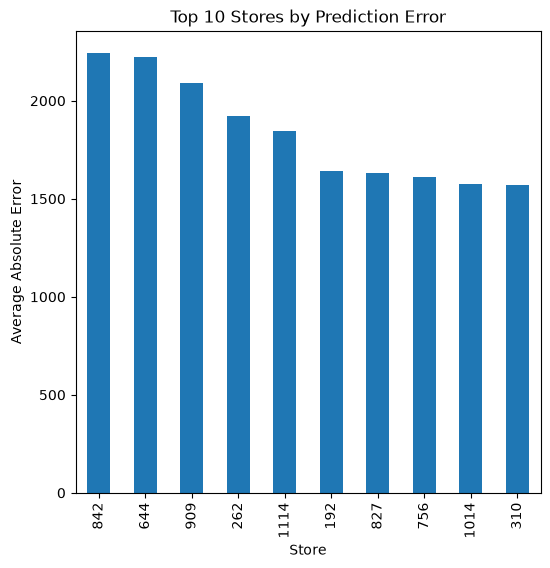

In [79]:
plt.figure(figsize=(6,6))
store_error.head(10).plot(kind='bar')
plt.title('Top 10 Stores by Prediction Error')
plt.xlabel('Store')
plt.ylabel('Average Absolute Error')

plt.show()

In [80]:
error_analysis = error_analysis.merge(df_model[['date' , 'store' , 'dayofweek']], on=['date' , 'store'] , how='left')

In [81]:
day_error = (error_analysis.groupby('dayofweek')['absolute_error'].mean())
day_error

dayofweek
0     647.764651
1     631.985633
2     729.544076
3     667.049086
4     843.316460
5    1018.795193
6    1271.504812
Name: absolute_error, dtype: float64

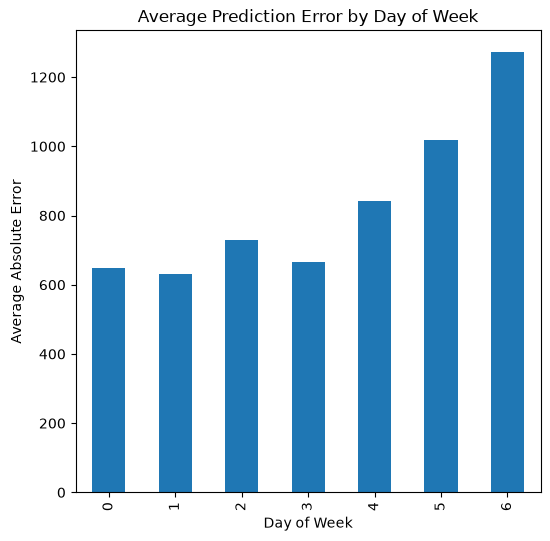

In [82]:
plt.figure(figsize = (6,6))

day_error.plot(kind='bar')
plt.title('Average Prediction Error by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Absolute Error')

plt.show()

In [83]:
store_error = (error_analysis.groupby('store').agg(
    mean_absolute_error = ('absolute_error', 'mean'),
    mean_error = ('error' , 'mean'),
    count = ('error' , 'count')).sort_values('mean_absolute_error' , ascending = False))

store_error.head()

,mean_absolute_error,mean_error,count
store,,,
842,2244.456432,787.196949,145
644,2224.302992,440.750750,123
909,2092.368012,595.366118,132
262,1922.179016,724.590693,176
1114,1843.370416,1307.015585,147


In [84]:
worst_features = test_data[
    [
        'date',
        'store',
        'sales',
        'target',
        'promo',
        'schoolholiday',
        'dayofweek',
        'lag_1',
        'lag_7',
        'lag_14',
        'lag_28',
        'rolling_mean_7',
        'rolling_mean_14',
        'rolling_mean_28',
        'rolling_std_7',
        'rolling_std_28'
    ]
].copy()

worst_features['predicted_sales'] = xgb_pred

worst_features['error'] = (worst_features['target'] - worst_features['predicted_sales'])

worst_features['absolute_error'] = (worst_features['error'].abs())

worst_features = worst_features.sort_values('absolute_error' , ascending = False)

worst_features.head(20)

,date,store,sales,target,promo,schoolholiday,dayofweek,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_std_7,rolling_std_28,predicted_sales,error,absolute_error
46623,2015-06-20,909,22882,41551.0,0,0,5,11856.0,9113.0,8868.0,10480.0,10652.142857,9204.357143,8868.000000,5291.195216,5232.614289,9243.957031,32307.042969,32307.042969
44393,2015-06-22,909,41551,30038.0,0,0,0,0.0,16602.0,9352.0,0.0,12619.142857,10205.357143,9310.928571,6929.373503,5861.257809,9180.994141,20857.005859,20857.005859
192423,2015-02-09,644,22970,28242.0,0,0,0,0.0,9607.0,10105.0,10148.0,8508.142857,8507.071429,7995.214286,3865.178540,3569.844559,7605.354492,20636.645508,20636.645508
88346,2015-05-13,262,21861,38367.0,0,1,2,16489.0,18698.0,19737.0,18241.0,20490.857143,22727.357143,21389.785714,4980.924661,5490.331902,17842.251953,20524.748047,20524.748047
38201,2015-06-27,292,3278,29161.0,0,0,5,5172.0,3479.0,3739.0,3853.0,4370.571429,5031.642857,5161.035714,2084.365120,2552.392450,9595.926758,19565.073242,19565.073242
186878,2015-02-14,674,2401,0.0,0,0,5,7438.0,5604.0,5650.0,4914.0,4928.285714,9704.071429,7965.964286,2561.987947,6485.536766,16762.230469,-16762.230469,16762.230469
76081,2015-05-24,262,30978,35159.0,0,0,6,18179.0,29008.0,31527.0,28853.0,20864.285714,22122.000000,22596.892857,3831.117971,6038.538162,18849.298828,16309.701172,16309.701172
134061,2015-04-02,262,30012,38722.0,1,0,3,26738.0,17519.0,17551.0,19875.0,21594.714286,19872.642857,19584.714286,4247.217274,4321.211292,22886.250000,15835.750000,15835.750000
191308,2015-02-10,644,28242,26818.0,0,0,1,22970.0,10160.0,8326.0,10127.0,10417.142857,9426.000000,8453.142857,6733.813789,4545.329289,11135.485352,15682.514648,15682.514648
35971,2015-06-29,292,29161,23584.0,1,0,0,0.0,6028.0,8984.0,8563.0,4341.857143,4998.714286,5140.500000,2100.020193,2565.585292,7930.909668,15653.090332,15653.090332


# 9. ADVANCED FEATURE ENGINEERING & RE-SPLIT

In [85]:
df['trend_7_28'] = (df['rolling_mean_7'] / (df['rolling_mean_28'] + 1)) 

In [86]:
df['lag1_vs_lag7'] = (df['lag_1'] / (df['lag_7'] + 1))

In [87]:
df['weekofyear'] = df['date'].dt.isocalendar().week.astype(int)
df['quarter'] = df['date'].dt.quarter

In [88]:
df_model = df[df['open'] ==1].copy()
df_model = df_model.sort_values(['store' , 'date'])
df_model['target'] = (df_model.groupby('store')['sales'].shift(-1))

In [89]:
df_model = df_model.dropna(
    subset=[
        'lag_1',
        'lag_7',
        'lag_14',
        'lag_28',
        'rolling_mean_7',
        'rolling_mean_14',
        'rolling_mean_28',
        'rolling_std_7',
        'rolling_std_28',
        'trend_7_28',
        'lag1_vs_lag7',
        'target'
    ]
)

In [90]:
features = [
    'store',
    'promo',
    'schoolholiday',
    'competitiondistance',
    'promo2',

    'year',
    'month',
    'day',
    'dayofweek',
    'weekofyear',
    'quarter',
    'is_weekend',

    'lag_1',
    'lag_7',
    'lag_14',
    'lag_28',

    'rolling_mean_7',
    'rolling_mean_14',
    'rolling_mean_28',
    'rolling_std_7',
    'rolling_std_28',

    'trend_7_28',
    'lag1_vs_lag7',

    'storetype',
    'assortment',
    'stateholiday'
]

In [91]:
X = df_model[features]
y = df_model['target']

In [92]:
df_model = df_model.sort_values('date')

split = int(len(df_model) * 0.8)

train_data = df_model.iloc[:split].copy()
test_data = df_model.iloc[split:].copy()

X_train = train_data[features]
y_train = train_data['target']

X_test = test_data[features]
y_test = test_data['target']

In [93]:
X_train = pd.get_dummies(
    X_train,
    columns=['storetype', 'assortment', 'stateholiday'],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=['storetype', 'assortment', 'stateholiday'],
    drop_first=True
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [94]:
print(X_train.shape)
print(X_test.shape)

print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

(654184, 32)
(163546, 32)
0
0


In [95]:
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

In [96]:
xgb_mae = mean_absolute_error(y_test, xgb_pred)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_pred)
)

xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 759.193590186833
XGBoost RMSE: 1103.7296718145017
XGBoost R2: 0.869898700023254


In [97]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred_new = lr.predict(X_test)

lr_mae_new = mean_absolute_error(y_test, lr_pred_new)
lr_rmse_new = np.sqrt(mean_squared_error(y_test, lr_pred_new))
lr_r2_new = r2_score(y_test, lr_pred_new)

print("Linear Regression MAE:", lr_mae_new)
print("Linear Regression RMSE:", lr_rmse_new)
print("Linear Regression R2:", lr_r2_new)

Linear Regression MAE: 1071.5301316422767
Linear Regression RMSE: 1507.6562903784786
Linear Regression R2: 0.7572490778946219


In [98]:
rf = RandomForestRegressor(n_estimators = 100 , random_state = 42 , n_jobs = 1)
rf.fit(X_train , y_train)
rf_pred_new = rf.predict(X_test)

rf_mae_new = mean_absolute_error(y_test, rf_pred_new)
rf_rmse_new = np.sqrt(mean_squared_error(y_test, rf_pred_new))
rf_r2_new = r2_score(y_test, rf_pred_new)

print("Random Forest MAE:", rf_mae_new)
print("Random Forest RMSE:", rf_rmse_new)
print("Random Forest R2:", rf_r2_new)

Random Forest MAE: 760.7277328091179
Random Forest RMSE: 1152.8912545665214
Random Forest R2: 0.8580508194494292


In [99]:
baseline_pred_new = X_test['lag_1']

baseline_mae_new = mean_absolute_error(y_test,baseline_pred_new)

baseline_rmse_new = np.sqrt(mean_squared_error(y_test, baseline_pred_new))

baseline_r2_new = r2_score(y_test,baseline_pred_new)

print("Baseline MAE:", baseline_mae_new)
print("Baseline RMSE:", baseline_rmse_new)
print("Baseline R2:", baseline_r2_new)

Baseline MAE: 2617.137802208553
Baseline RMSE: 3905.727024947457
Baseline R2: -0.6291458771038405


In [100]:
results_final = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest',
        'XGBoost'
    ],

    'MAE': [
        baseline_mae_new,
        lr_mae_new,
        rf_mae_new,
        xgb_mae
    ],

    'RMSE': [
        baseline_rmse_new,
        lr_rmse_new,
        rf_rmse_new,
        xgb_rmse
    ],

    'R2': [
        baseline_r2_new,
        lr_r2_new,
        rf_r2_new,
        xgb_r2
    ]
})

results_final

,Model,MAE,RMSE,R2
0,Baseline,2617.137802,3905.727025,-0.629146
1,Linear Regression,1071.530132,1507.656290,0.757249
2,Random Forest,760.727733,1152.891255,0.858051
3,XGBoost,759.193590,1103.729672,0.869899


# 10. HYPERPARAMETER TUNING & MODEL OPTIMIZATION

In [101]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators' : [300 , 500 , 700 , 900],
    'learning_rate' : [0.03 , 0.05 , 0.07 , 0.1],
    'max_depth' : [5 , 7 , 8 , 10],
    'subsample' : [0.8 , 1.0],
    'colsample_bytree' : [0.8 , 1.0]}

In [102]:
xgb_base=  XGBRegressor(random_state = 42)

random_search = RandomizedSearchCV(estimator=xgb_base , param_distributions = param_grid , n_iter = 15 , scoring = 'neg_mean_absolute_error' , cv = 3 , random_state = 42 , n_jobs = 1)
random_search.fit(X_train , y_train)

print('Best Parameters:')
print(random_search.best_params_)

Best Parameters:
{'subsample': 0.8, 'n_estimators': 900, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [103]:
tuned_xgb = XGBRegressor(n_estimators = 900 , learning_rate = 0.03 , max_depth = 10 , subsample = 0.8 , colsample_bytree = 0.8 , random_state = 42)

tuned_xgb.fit(X_train , y_train)

tuned_pred = tuned_xgb.predict(X_test)

In [104]:
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test , tuned_pred)

print("Tuned XGBoost MAE:", tuned_mae)
print("Tuned XGBoost RMSE:", tuned_rmse)
print("Tuned XGBoost R2:", tuned_r2)

Tuned XGBoost MAE: 723.8760537965329
Tuned XGBoost RMSE: 1070.592880818421
Tuned XGBoost R2: 0.877593381011326


In [105]:
tuning_comparison = pd.DataFrame({
    'Model': [
        'Original XGBoost',
        'Tuned XGBoost'
    ],
    'MAE': [
        xgb_mae,
        tuned_mae
    ],
    'RMSE': [
        xgb_rmse,
        tuned_rmse
    ],
    'R2': [
        xgb_r2,
        tuned_r2
    ]
})
tuning_comparison

,Model,MAE,RMSE,R2
0,Original XGBoost,759.193590,1103.729672,0.869899
1,Tuned XGBoost,723.876054,1070.592881,0.877593


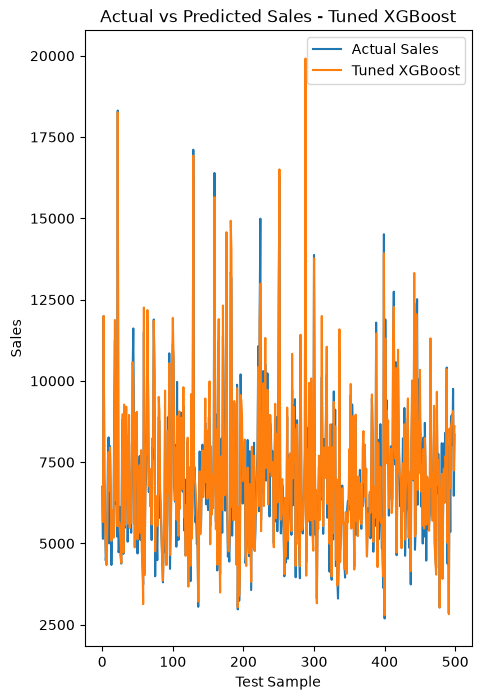

In [106]:
plt.figure(figsize=(5,8))

plt.plot(y_test.values[:500] , label = 'Actual Sales')
plt.plot(tuned_pred[:500] , label = 'Tuned XGBoost')
plt.title('Actual vs Predicted Sales - Tuned XGBoost')
plt.xlabel('Test Sample')
plt.ylabel('Sales')
plt.legend()

plt.show()

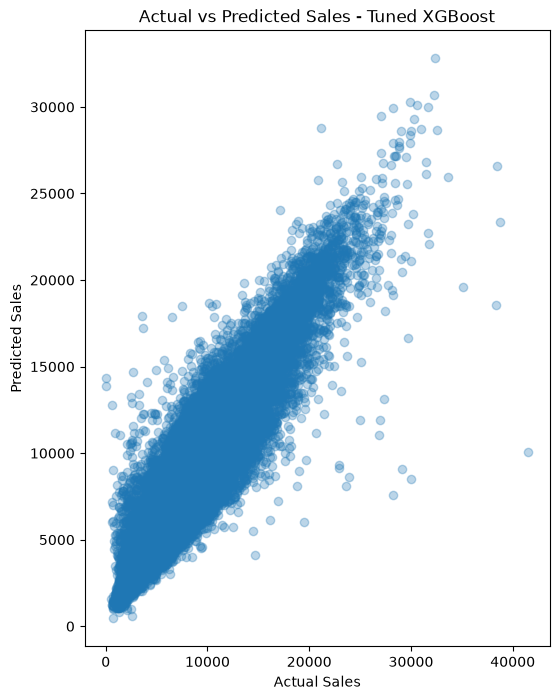

In [107]:
plt.figure(figsize = (6,8))

plt.scatter(y_test , tuned_pred , alpha = 0.3)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales - Tuned XGBoost')

plt.show()

In [108]:
tuned_residuals = y_test - tuned_pred

In [109]:
tuned_residuals.describe()

count    163546.000000
mean        -27.993977
std        1070.230095
min      -14399.236328
25%        -522.723511
50%         -30.690918
75%         469.596802
max       31507.842773
Name: target, dtype: float64

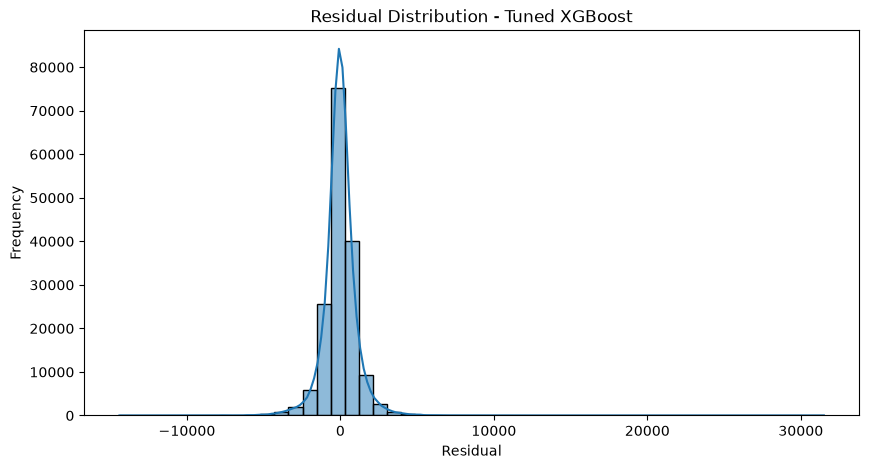

In [110]:
plt.figure(figsize=(10, 5))

sns.histplot(tuned_residuals,bins=50,kde=True)

plt.title('Residual Distribution - Tuned XGBoost')
plt.xlabel('Residual')
plt.ylabel('Frequency')

plt.show()

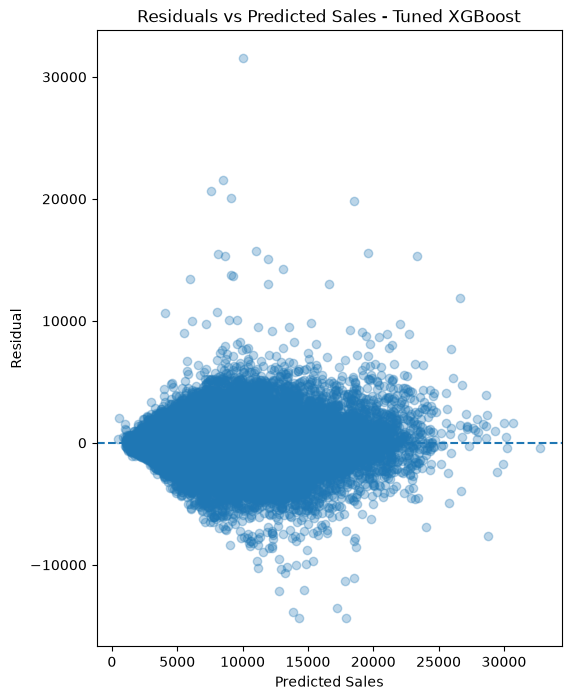

In [111]:
plt.figure(figsize = (6,8))
plt.scatter(tuned_pred, tuned_residuals , alpha = 0.3)
plt.axhline(y=0 , linestyle = '--')
plt.xlabel('Predicted Sales')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted Sales - Tuned XGBoost')

plt.show()

In [112]:
tuned_importance = pd.Series(tuned_xgb.feature_importances_,index=X_train.columns).sort_values(ascending= False)
tuned_importance.head(15)

rolling_mean_28    0.392273
is_weekend         0.120754
promo              0.115833
rolling_mean_14    0.082655
dayofweek          0.042316
storetype_b        0.020551
weekofyear         0.018940
trend_7_28         0.018644
rolling_mean_7     0.016831
day                0.016603
lag_1              0.014384
storetype_d        0.012365
quarter            0.011433
storetype_c        0.011296
rolling_std_28     0.009847
dtype: float32

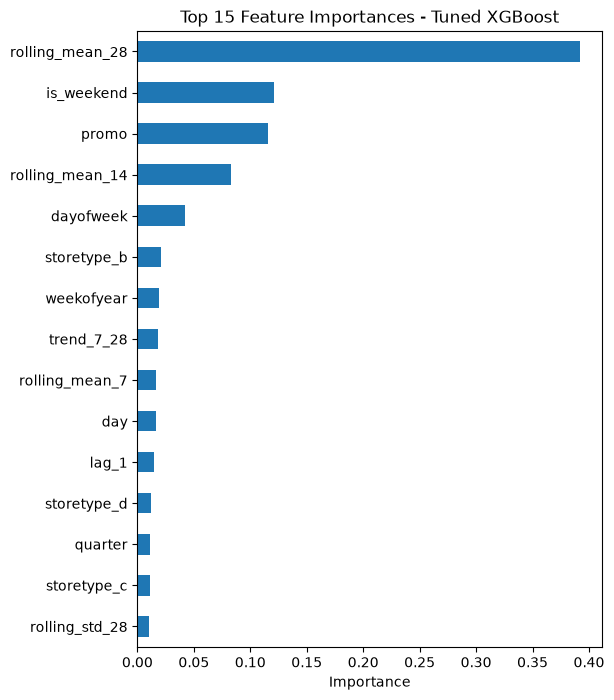

In [113]:
plt.figure(figsize = (6,8))

tuned_importance.head(15).sort_values().plot(kind = 'barh')
plt.title('Top 15 Feature Importances - Tuned XGBoost')
plt.xlabel('Importance')

plt.show()

In [114]:
final_errors = test_data[['date' , 'store' , 'sales' , 'target']].copy()

final_errors['predicted_sales'] = tuned_pred

final_errors['error'] = (final_errors['target'] - final_errors['predicted_sales'])
final_errors['absolute_error'] = (final_errors['error'].abs())

In [115]:
worst_final = final_errors.sort_values('absolute_error',ascending=False).head(20)

worst_final

,date,store,sales,target,predicted_sales,error,absolute_error
46623,2015-06-20,909,22882,41551.0,10043.157227,31507.842773,31507.842773
44393,2015-06-22,909,41551,30038.0,8494.737305,21543.262695,21543.262695
192423,2015-02-09,644,22970,28242.0,7606.866699,20635.133301,20635.133301
38201,2015-06-27,292,3278,29161.0,9081.450195,20079.549805,20079.549805
88346,2015-05-13,262,21861,38367.0,18532.806641,19834.193359,19834.193359
191308,2015-02-10,644,28242,26818.0,11063.931641,15754.068359,15754.068359
76081,2015-05-24,262,30978,35159.0,19604.056641,15554.943359,15554.943359
35971,2015-06-29,292,29161,23584.0,8118.390625,15465.609375,15465.609375
134061,2015-04-02,262,30012,38722.0,23367.023438,15354.976562,15354.976562
28750,2015-07-06,876,27330,23927.0,8630.387695,15296.612305,15296.612305


In [117]:
store_error_analysis = (
    final_errors
    .groupby('store')
    .agg(
        mean_absolute_error=('absolute_error', 'mean')
    )
    .reset_index()
    .merge(
        store_info,
        on='store',
        how='left'
    )
)

store_error_analysis.groupby(
    'storetype'
)['mean_absolute_error'].mean()

storetype
a    704.669004
b    996.484961
c    732.509834
d    737.810001
Name: mean_absolute_error, dtype: float64

In [118]:
final_errors['promo'] = test_data['promo'].values

In [119]:
final_promo_error = (final_errors.groupby('promo')['absolute_error'].mean())

final_promo_error

promo
0    717.258300
1    732.424736
Name: absolute_error, dtype: float64

In [120]:
final_errors['dayofweek'] = test_data['dayofweek'].values

final_day_error = (final_errors.groupby('dayofweek')['absolute_error'].mean())

final_day_error

dayofweek
0     612.915883
1     621.364906
2     725.690367
3     614.381604
4     680.392192
5    1059.150533
6    1277.291570
Name: absolute_error, dtype: float64

# 11. FINAL ERROR & PERCENTAGE METRICS

In [121]:
non_zero = y_test != 0

mape = (np.mean(np.abs((y_test[non_zero] - tuned_pred[non_zero])/ y_test[non_zero])) * 100)

print("MAPE:", mape)

MAPE: 11.169194490953494


In [122]:
smape = (np.mean(2 * np.abs(y_test - tuned_pred) /(np.abs(y_test) + np.abs(tuned_pred) + 1e-8)) * 100)

print("SMAPE:", smape)

SMAPE: 10.520382070263489


In [123]:
final_store_error = (final_errors.groupby('store')['absolute_error'].mean().sort_values(ascending=False))

final_store_error.head(15)

store
644     2189.198266
842     2146.897394
909     2109.954457
262     1736.212142
1114    1730.349782
756     1569.284213
1014    1543.566276
192     1543.045256
335     1522.712216
259     1491.865517
876     1482.550448
279     1443.762790
310     1443.268263
827     1440.500033
1027    1436.530207
Name: absolute_error, dtype: float64

In [126]:
store_info = df_model[['store', 'storetype', 'assortment', 'competitiondistance']].drop_duplicates('store')

store_error_analysis = (final_store_error.reset_index().merge(store_info , on = 'store' , how='left'))

store_error_analysis.head(15)

,store,absolute_error,storetype,assortment,competitiondistance
0,644,2189.198266,c,a,4030.0
1,842,2146.897394,d,c,1200.0
2,909,2109.954457,a,c,1680.0
3,262,1736.212142,b,a,1180.0
4,1114,1730.349782,a,c,870.0
5,756,1569.284213,a,c,50.0
6,1014,1543.566276,a,c,210.0
7,192,1543.045256,d,c,2770.0
8,335,1522.712216,b,a,90.0
9,259,1491.865517,b,b,210.0


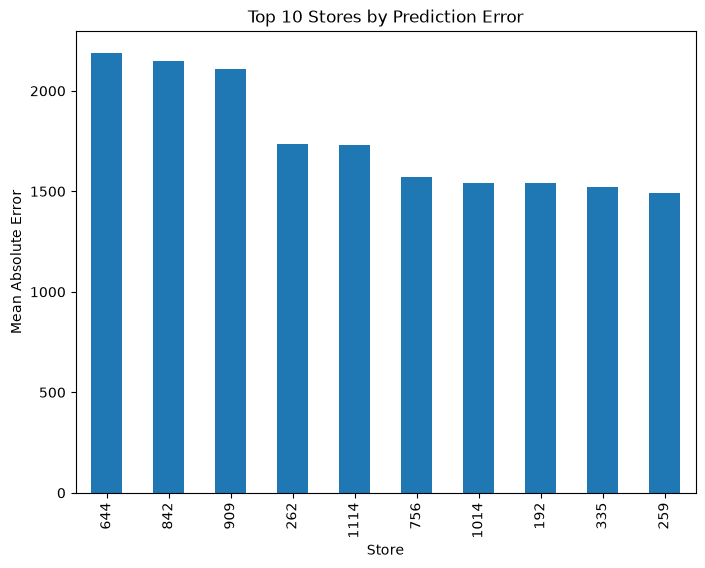

In [127]:
plt.figure(figsize=(8, 6))

final_store_error.head(10).plot(kind='bar')

plt.title('Top 10 Stores by Prediction Error')
plt.xlabel('Store')
plt.ylabel('Mean Absolute Error')

plt.show()

# 12. PRODUCTION ARTIFACT EXPORT

In [128]:
import joblib

joblib.dump(
    tuned_xgb,
    'rossmann_xgboost_model.pkl'
)

['rossmann_xgboost_model.pkl']

In [129]:
joblib.dump(
    list(X_train.columns),
    'rossmann_features.pkl'
)

['rossmann_features.pkl']

In [130]:
final_metrics = pd.DataFrame({
    'Metric': [
        'MAE',
        'RMSE',
        'R2',
        'MAPE',
        'SMAPE'
    ],
    'Value': [
        tuned_mae,
        tuned_rmse,
        tuned_r2,
        mape,
        smape
    ]
})

final_metrics

,Metric,Value
0,MAE,723.876054
1,RMSE,1070.592881
2,R2,0.877593
3,MAPE,11.169194
4,SMAPE,10.520382


In [131]:
final_comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest',
        'Original XGBoost',
        'Tuned XGBoost'
    ],
    'MAE': [
        baseline_mae_new,
        lr_mae_new,
        rf_mae_new,
        xgb_mae,
        tuned_mae
    ],
    'RMSE': [
        baseline_rmse_new,
        lr_rmse_new,
        rf_rmse_new,
        xgb_rmse,
        tuned_rmse
    ],
    'R2': [
        baseline_r2_new,
        lr_r2_new,
        rf_r2_new,
        xgb_r2,
        tuned_r2
    ]
})

final_comparison

,Model,MAE,RMSE,R2
0,Baseline,2617.137802,3905.727025,-0.629146
1,Linear Regression,1071.530132,1507.656290,0.757249
2,Random Forest,760.727733,1152.891255,0.858051
3,Original XGBoost,759.193590,1103.729672,0.869899
4,Tuned XGBoost,723.876054,1070.592881,0.877593


# 13. INFERENCE & DYNAMIC FORECASTING PIPELINE

In [132]:
model = joblib.load('rossmann_xgboost_model.pkl')

feature_columns = joblib.load('rossmann_features.pkl')

def predict_sales(X_new):
    """Predict Rossmann sales for new data."""
    
    X_new = X_new.reindex(columns=feature_columns, fill_value=0)

    predictions = model.predict(X_new)

    return predictions

In [133]:
sample = X_test.iloc[[0]]

prediction = predict_sales(sample)

print("Predicted Sales:", prediction[0])
print("Actual Sales:", y_test.iloc[0])

Predicted Sales: 6710.996
Actual Sales: 6744.0


In [134]:
print("Number of features:", len(feature_columns))
print("\nFeatures used by model:")
print(feature_columns)

Number of features: 32

Features used by model:
['store', 'promo', 'schoolholiday', 'competitiondistance', 'promo2', 'year', 'month', 'day', 'dayofweek', 'weekofyear', 'quarter', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28', 'rolling_std_7', 'rolling_std_28', 'trend_7_28', 'lag1_vs_lag7', 'storetype_b', 'storetype_c', 'storetype_d', 'assortment_b', 'assortment_c', 'stateholiday_0', 'stateholiday_a', 'stateholiday_b', 'stateholiday_c']


In [135]:
def prepare_prediction_data(store_history):
    
    data = store_history.copy()
    
    data['date'] = pd.to_datetime(data['date'])
    
    data = data.sort_values('date')
    
    data['year'] = data['date'].dt.year
    data['month'] = data['date'].dt.month
    data['day'] = data['date'].dt.day
    data['dayofweek'] = data['date'].dt.dayofweek
    data['weekofyear'] = data['date'].dt.isocalendar().week.astype(int)
    data['quarter'] = data['date'].dt.quarter
    data['is_weekend'] = (data['dayofweek'] >= 5).astype(int)
    
    data['lag_1'] = data['sales'].shift(1)
    data['lag_7'] = data['sales'].shift(7)
    data['lag_14'] = data['sales'].shift(14)
    data['lag_28'] = data['sales'].shift(28)
    
    data['rolling_mean_7'] = (
        data['sales'].shift(1).rolling(7).mean()
    )
    
    data['rolling_mean_14'] = (
        data['sales'].shift(1).rolling(14).mean()
    )
    
    data['rolling_mean_28'] = (
        data['sales'].shift(1).rolling(28).mean()
    )
    
    data['rolling_std_7'] = (
        data['sales'].shift(1).rolling(7).std()
    )
    
    data['rolling_std_28'] = (
        data['sales'].shift(1).rolling(28).std()
    )
    
    data['trend_7_28'] = (
        data['rolling_mean_7'] /
        (data['rolling_mean_28'] + 1)
    )
    
    data['lag1_vs_lag7'] = (
        data['lag_1'] /
        (data['lag_7'] + 1)
    )
    
    return data

In [136]:
store_id = 1

store_history = df[df['store'] == store_id].copy()

prepared_data = prepare_prediction_data(store_history)

prepared_data.tail()

,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,...,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_std_7,rolling_std_28,trend_7_28,lag1_vs_lag7,weekofyear,quarter
4460,1,0,2015-07-27,6102,612,1,1,0,1,c,...,5197.0,3322.285714,3700.285714,3786.428571,1510.844214,1694.177205,0.877188,0.000000,31,3
3345,1,1,2015-07-28,5011,560,1,1,0,1,c,...,5735.0,3566.142857,3775.142857,3818.750000,1819.145077,1730.331709,0.933606,1.714527,31,3
2230,1,2,2015-07-29,4782,523,1,1,0,1,c,...,5223.0,3773.714286,3772.928571,3792.892857,1899.196208,1705.872392,0.994681,1.446176,31,3
1115,1,3,2015-07-30,5020,546,1,1,0,1,c,...,5558.0,3962.000000,3774.000000,3777.142857,1928.481008,1694.175178,1.048663,1.268435,31,3
0,1,4,2015-07-31,5263,555,1,1,0,1,c,...,4665.0,4140.714286,3816.357143,3757.928571,1965.230157,1676.185063,1.101568,1.354195,31,3


In [137]:
prepared_open =prepared_data[prepared_data['open'] == 1].copy()

latest_row = prepared_data.sort_values('date').iloc[[-1]].copy()

latest_row = pd.get_dummies(latest_row , columns=['storetype', 'assortment', 'stateholiday'], dtype = int)

X_new = latest_row.reindex(columns = feature_columns , fill_value =0)

print("Input shape:", X_new.shape)
print("Number of features:", len(X_new.columns))
print(X_new.head())

Input shape: (1, 32)
Number of features: 32
   store  promo  schoolholiday  competitiondistance  promo2  year  month  day  \
0      1      1              1               1270.0       0  2015      7   31   

   dayofweek  weekofyear  ...  lag1_vs_lag7  storetype_b  storetype_c  \
0          4          31  ...      1.354195            0            1   

   storetype_d  assortment_b  assortment_c  stateholiday_0  stateholiday_a  \
0            0             0             0               1               0   

   stateholiday_b  stateholiday_c  
0               0               0  

[1 rows x 32 columns]


In [138]:
prediction = predict_sales(X_new)

print("Store:", store_id)
print("Latest historical date:", latest_row['date'].iloc[0])
print("Predicted sales:", round(float(prediction[0]), 2))

Store: 1
Latest historical date: 2015-07-31 00:00:00
Predicted sales: 4861.6


In [139]:
future_date = pd.Timestamp('2015-08-01')

print("Forecast date:", future_date)
print("Day:", future_date.day)
print("Day of week:", future_date.dayofweek)
print("Week:", future_date.isocalendar().week)

Forecast date: 2015-08-01 00:00:00
Day: 1
Day of week: 5
Week: 31


In [140]:
latest = prepared_open.sort_values('date').iloc[-1].copy()

future_row = pd.DataFrame({
    'store': [store_id],
    'date': [future_date],
    'promo': [latest['promo']],
    'schoolholiday': [latest['schoolholiday']],
    'competitiondistance': [latest['competitiondistance']],
    'promo2': [latest['promo2']],
    'storetype': [latest['storetype']],
    'assortment': [latest['assortment']],
    'stateholiday': [latest['stateholiday']]
})

future_row

,store,date,promo,schoolholiday,competitiondistance,promo2,storetype,assortment,stateholiday
0,1,2015-08-01,1,1,1270.0,0,c,a,0


In [141]:
history = prepared_open.sort_values('date').copy()

future_row['year'] = future_date.year
future_row['month'] = future_date.month
future_row['day'] = future_date.day
future_row['dayofweek'] = future_date.dayofweek
future_row['weekofyear'] = int(future_date.isocalendar().week)
future_row['quarter'] = future_date.quarter
future_row['is_weekend'] = int(future_date.dayofweek >= 5)

future_row['lag_1'] = history['sales'].iloc[-1]
future_row['lag_7'] = history['sales'].iloc[-7]
future_row['lag_14'] = history['sales'].iloc[-14]
future_row['lag_28'] = history['sales'].iloc[-28]

future_row['rolling_mean_7'] = history['sales'].iloc[-7:].mean()
future_row['rolling_mean_14'] = history['sales'].iloc[-14:].mean()
future_row['rolling_mean_28'] = history['sales'].iloc[-28:].mean()

future_row['rolling_std_7'] = history['sales'].iloc[-7:].std()
future_row['rolling_std_28'] = history['sales'].iloc[-28:].std()

future_row['trend_7_28'] = (
    future_row['rolling_mean_7'] /
    (future_row['rolling_mean_28'] + 1)
)

future_row['lag1_vs_lag7'] = (
    future_row['lag_1'] /
    (future_row['lag_7'] + 1)
)

future_row

,store,date,promo,schoolholiday,competitiondistance,promo2,storetype,assortment,stateholiday,year,...,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_std_7,rolling_std_28,trend_7_28,lag1_vs_lag7
0,1,2015-08-01,1,1,1270.0,0,c,a,0,2015,...,3706,4427,5735,4892.571429,4508.5,4535.75,744.95679,719.865297,1.078431,1.419746


In [142]:
future_encoded = pd.get_dummies(future_row , columns = ['storetype' , 'assortment' , 'stateholiday'] , dtype = int)

X_future = future_encoded.reindex(columns = feature_columns , fill_value = 0)

future_prediction = predict_sales(X_future)

print("Store:", store_id)
print("Forecast date:", future_date.date())
print("Predicted sales:", round(float(future_prediction[0]), 2))

Store: 1
Forecast date: 2015-08-01
Predicted sales: 5560.6


In [143]:
def forecast_store_sales(
    store_id,
    forecast_date,
    promo,
    schoolholiday
):
    
    # Get historical data for the store
    history = df[
        (df['store'] == store_id) &
        (df['open'] == 1)
    ].copy()
    
    history = history.sort_values('date')
    
    forecast_date = pd.Timestamp(forecast_date)
    
    # Get latest store information
    latest = history.iloc[-1]
    
    # Create future row
    future = pd.DataFrame({
        'store': [store_id],
        'date': [forecast_date],
        'promo': [promo],
        'schoolholiday': [schoolholiday],
        'competitiondistance': [latest['competitiondistance']],
        'promo2': [latest['promo2']],
        'storetype': [latest['storetype']],
        'assortment': [latest['assortment']],
        'stateholiday': [latest['stateholiday']]
    })
    
    # Calendar features
    future['year'] = forecast_date.year
    future['month'] = forecast_date.month
    future['day'] = forecast_date.day
    future['dayofweek'] = forecast_date.dayofweek
    future['weekofyear'] = int(forecast_date.isocalendar().week)
    future['quarter'] = forecast_date.quarter
    future['is_weekend'] = int(forecast_date.dayofweek >= 5)
    
    # Lag features
    future['lag_1'] = history['sales'].iloc[-1]
    future['lag_7'] = history['sales'].iloc[-7]
    future['lag_14'] = history['sales'].iloc[-14]
    future['lag_28'] = history['sales'].iloc[-28]
    
    # Rolling features
    future['rolling_mean_7'] = history['sales'].iloc[-7:].mean()
    future['rolling_mean_14'] = history['sales'].iloc[-14:].mean()
    future['rolling_mean_28'] = history['sales'].iloc[-28:].mean()
    
    future['rolling_std_7'] = history['sales'].iloc[-7:].std()
    future['rolling_std_28'] = history['sales'].iloc[-28:].std()
    
    # Ratio features
    future['trend_7_28'] = (
        future['rolling_mean_7'] /
        (future['rolling_mean_28'] + 1)
    )
    
    future['lag1_vs_lag7'] = (
        future['lag_1'] /
        (future['lag_7'] + 1)
    )
    
    # One-hot encoding
    future = pd.get_dummies(
        future,
        columns=['storetype', 'assortment', 'stateholiday'],
        dtype=int
    )
    
    # Match training feature structure
    X_future = future.reindex(
        columns=feature_columns,
        fill_value=0
    )
    
    # Predict
    prediction = model.predict(X_future)[0]
    
    return prediction

# **Final Prediction**

In [144]:
prediction = forecast_store_sales(
    store_id=1,
    forecast_date='2015-08-01',
    promo=1,
    schoolholiday=1
)

print("Predicted sales:", round(prediction, 2))

Predicted sales: 5560.6
